# medroute: demonstração completa

Fluxo ponta a ponta na instância `sp_40` (40 entregas a partir da Farmácia Central do HC-FMUSP, frota de 2 motos, 2 carros e 1 van):

1. dados da instância e da frota;
2. GA híbrido (giant tour + split ótimo, semente NN e 2-opt nas rotas) com o fitness em R$;
3. comparação com os baselines avaliados pelo mesmo fitness e o mesmo split;
4. rotas no mapa e curva de convergência;
5. LLM: instruções por motorista, relatório semanal e pergunta em linguagem natural.

**Como rodar:** na raiz do repositório, com o ambiente do README, instale o extra do notebook (`python -m pip install -e ".[notebook]"`) e abra este arquivo no Jupyter ou no VS Code. A mesma demonstração roda no terminal com `medroute demo` (ou `medroute demo --rapido`).

A LLM está em `mock` (sem rede, sem custo): ela devolve os fatos que receberia, montados em Python, em vez de redigir o texto. Para ver as respostas reais, troque `PROVEDOR` para `"openai"` ou `"groq"` (chave no `.env`).

In [1]:
import os
from pathlib import Path

if not (Path.cwd() / "configs").exists():  # aberto de dentro de notebooks/
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from IPython.display import Markdown, display

from medroute.baselines import (
    solve_nearest_neighbor,
    solve_nearest_neighbor_two_opt,
    solve_savings,
)
from medroute.data import DistanceMatrix, load_fleet, load_instance
from medroute.ga import GAConfig, GeneticAlgorithm, load_fitness_config, make_fitness
from medroute.llm import answer, client_from_env, generate_instructions, generate_report
from medroute.viz import build_map

PROVEDOR = "mock"  # "openai" ou "groq" para respostas reais
SEED = 7
pd.set_option("display.precision", 2)

## 1. Instância e frota

In [2]:
fleet = load_fleet("configs/frota.yaml")
inst = load_instance("data/instances/sp_40.json", fleet)
dm = DistanceMatrix(inst, fleet)

entregas = pd.DataFrame([d.model_dump() for d in inst.deliveries])
print(f"{inst.nome}: {len(entregas)} entregas · depósito: {inst.depot.nome}")
display(
    entregas.groupby("prioridade").agg(
        entregas=("id", "count"),
        peso_kg=("peso_kg", "sum"),
        volume_l=("volume_l", "sum"),
        refrigeradas=("refrigerado", "sum"),
        com_prazo=("deadline_min", "count"),
    )
)
pd.DataFrame([v.model_dump() for v in inst.fleet]).set_index("id")

sp_40: 40 entregas · depósito: Farmácia Central HC-FMUSP


,entregas,peso_kg,volume_l,refrigeradas,com_prazo
prioridade,,,,,
alta,10,16.2,71.5,1,0
critica,6,42.4,220.2,1,6
normal,24,161.4,530.1,2,0


,tipo,capacidade_kg,capacidade_l,autonomia_km,velocidade_kmh,custo_km,custo_fixo,aceita_refrigerado
id,,,,,,,,
moto-01,moto,15.0,40.0,120.0,35.0,0.8,60.0,False
moto-02,moto,15.0,40.0,120.0,35.0,0.8,60.0,False
carro-01,carro,150.0,400.0,300.0,28.0,1.5,120.0,True
carro-02,carro,150.0,400.0,300.0,28.0,1.5,120.0,True
van-01,van,650.0,3100.0,400.0,24.0,2.5,200.0,True


## 2. GA híbrido

Mesma configuração das rodadas oficiais (`configs/experimentos/s2.yaml`, configuração `hibrido`): população 100, 300 gerações, OX, inversão, elitismo 2, torneio 3, semente do vizinho mais próximo e 2-opt em 30 % dos filhos. O fitness é o custo em R$: operacional (fixo + R$/km) + prioridade (R$/min até a chegada) + penalidades. Leva cerca de 2 minutos.

In [3]:
fitness_fn = make_fitness(inst, dm, fleet, load_fitness_config("configs/fitness.yaml"))
config = GAConfig(
    population_size=100,
    generations=300,
    crossover_rate=0.9,
    mutation_rate=0.2,
    elitism=2,
    tournament_size=3,
    crossover="ox",
    mutation="inversion",
    seed_nearest_neighbor=True,
    local_search_rate=0.3,
)
ga = GeneticAlgorithm(inst, dm, config, fitness_fn).run(SEED)

penalidades = sum(ga.penalidades.values())
prioridade = ga.fitness - ga.custo_operacional - penalidades
print(
    f"Fitness R$ {ga.fitness:.2f} = operacional R$ {ga.custo_operacional:.2f} "
    f"+ prioridade R$ {prioridade:.2f} + penalidades R$ {penalidades:.2f}"
)
print(f"{ga.distancia_total_km:.1f} km · {len(ga.routes)} veículos · {ga.tempo_exec_s:.0f} s")
pd.DataFrame(
    [
        {
            "veículo": r.vehicle_id,
            "entregas": len(r.sequence),
            "km": r.distancia_km,
            "min": r.duracao_min,
            "carga kg": r.carga_kg,
            "carga L": r.carga_l,
            "custo R$": r.custo,
            "violações": sum(r.violacoes.values()),
        }
        for r in ga.routes
    ]
).set_index("veículo")

Fitness R$ 1058.53 = operacional R$ 603.97 + prioridade R$ 454.56 + penalidades R$ 0.00
208.5 km · 4 veículos · 143 s


,entregas,km,min,carga kg,carga L,custo R$,violações
veículo,,,,,,,
carro-01,17,63.20,323.54,103.7,370.3,214.80,0.0
moto-01,7,57.07,195.17,11.7,39.6,105.66,0.0
moto-02,6,41.22,153.93,13.5,30.5,92.98,0.0
carro-02,10,47.02,221.62,91.1,381.4,190.53,0.0


## 3. Comparação com os baselines

Vizinho mais próximo, NN + 2-opt e Clarke-Wright Savings, todos avaliados pela mesma função de fitness e divididos em rotas pelo mesmo split do GA. Uma seed aqui; a comparação com 5 seeds e três configurações do GA está na seção 4: a seed 7 é a melhor das 5 do GA híbrido; na média, o híbrido fica 9 % abaixo do NN + 2-opt.

In [4]:
baselines = {
    "NN": solve_nearest_neighbor(inst, dm, seed=SEED, fitness_fn=fitness_fn),
    "NN + 2-opt": solve_nearest_neighbor_two_opt(inst, dm, seed=SEED, fitness_fn=fitness_fn),
    "Savings": solve_savings(inst, dm, seed=SEED, fitness_fn=fitness_fn),
}
ref = baselines["NN + 2-opt"].fitness
pd.DataFrame(
    [
        {
            "algoritmo": nome,
            "fitness R$": s.fitness,
            "× NN+2-opt": f"{100 * (s.fitness / ref - 1):+.1f} %",
            "km": s.distancia_total_km,
            "veículos": len(s.routes),
            "tempo s": round(s.tempo_exec_s, 2),
        }
        for nome, s in {"GA híbrido": ga, **baselines}.items()
    ]
).set_index("algoritmo").sort_values("fitness R$")

,fitness R$,× NN+2-opt,km,veículos,tempo s
algoritmo,,,,,
GA híbrido,1058.53,-16.2 %,208.51,4,143.14
NN + 2-opt,1263.23,+0.0 %,235.22,5,28.66
Savings,1318.14,+4.3 %,219.75,5,0.01
NN,1432.09,+13.4 %,275.05,5,0.01


## 4. Resultados oficiais (5 seeds)

Rodada de 19/10 com o runner (`medroute compare --config configs/experimentos/s2.yaml`), dados reais e fator de trânsito: média ± desvio-padrão do fitness em 5 seeds (7, 17, 42, 73, 101).

In [5]:
resumo = pd.read_csv("reports/comparativo-s2/summary.csv")
resumo = resumo[resumo.algoritmo != "random"]
resumo.assign(
    fitness=resumo.fitness_media.map("R$ {:,.2f}".format)
    + " ± "
    + resumo.fitness_dp.map("{:.2f}".format)
).pivot(index="algoritmo", columns="instance_nome", values="fitness")

instance_nome,sp_15,sp_40
algoritmo,,
ga_hibrido,R$ 458.64 ± 5.12,"R$ 1,145.65 ± 64.55"
ga_pmx,R$ 456.20 ± 3.18,"R$ 1,135.36 ± 72.57"
ga_puro,R$ 472.48 ± 20.67,"R$ 1,377.15 ± 119.34"
nearest_neighbor,R$ 474.44 ± 0.00,"R$ 1,432.09 ± 0.00"
nearest_neighbor_two_opt,R$ 461.72 ± 0.00,"R$ 1,263.23 ± 0.00"
savings,R$ 575.96 ± 0.00,"R$ 1,318.14 ± 0.00"


## 5. Rotas e convergência

Visão estática (aparece no GitHub) e, abaixo, o mapa interativo em folium (cor por veículo, ícone por prioridade), que só é exibido ao executar o notebook.

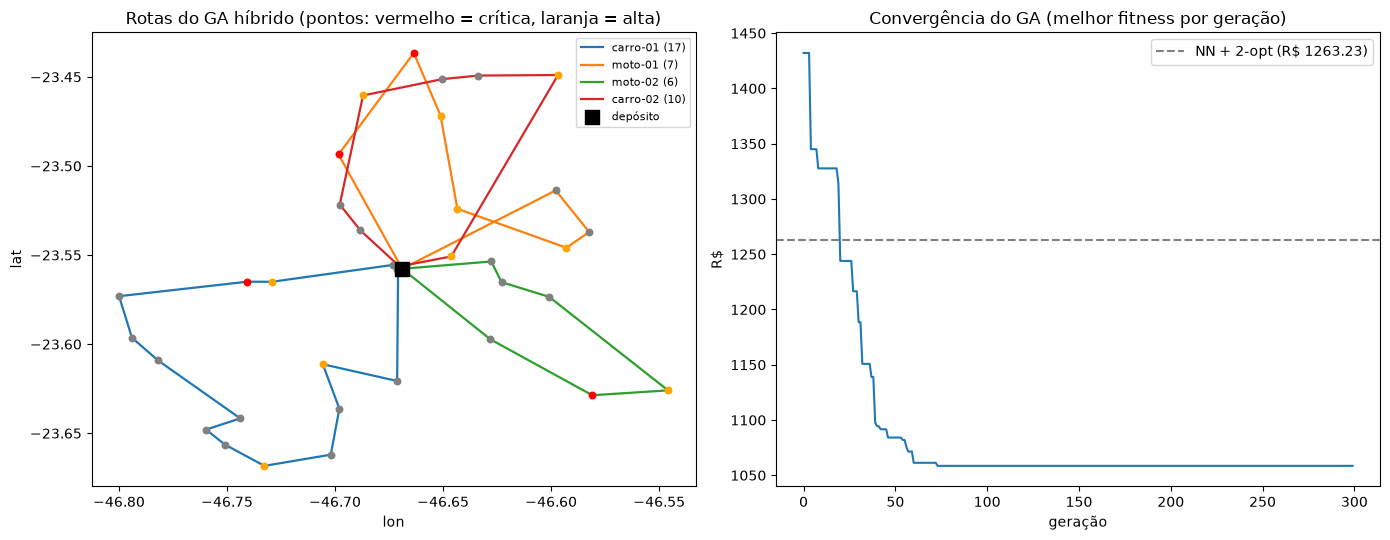

In [6]:
pos = {d.id: (d.lon, d.lat) for d in inst.deliveries}
deposito = (inst.depot.lon, inst.depot.lat)
cores = {"critica": "red", "alta": "orange", "normal": "grey"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for r in ga.routes:
    xs, ys = zip(*[deposito, *(pos[e] for e in r.sequence), deposito], strict=True)
    ax1.plot(xs, ys, "-", lw=1.6, label=f"{r.vehicle_id} ({len(r.sequence)})")
for d in inst.deliveries:
    ax1.scatter(d.lon, d.lat, s=22, color=cores[d.prioridade], zorder=3)
ax1.scatter(*deposito, marker="s", s=90, color="black", zorder=4, label="depósito")
titulo = "Rotas do GA híbrido (pontos: vermelho = crítica, laranja = alta)"
ax1.set(title=titulo, xlabel="lon", ylabel="lat")
ax1.legend(fontsize=8)

ax2.plot(ga.historico_fitness)
ax2.axhline(ref, color="grey", ls="--", label=f"NN + 2-opt (R$ {ref:.2f})")
ax2.set(title="Convergência do GA (melhor fitness por geração)", xlabel="geração", ylabel="R$")
ax2.legend()
plt.tight_layout()

In [7]:
build_map(ga, inst)

## 6. LLM

Os números (ordem das paradas, horários de chegada com trânsito, prazos, cargas) são calculados em Python e entregues prontos no prompt; a LLM só redige. Com `mock`, a saída é o próprio contexto enviado (mostrado em parte).

In [8]:
load_dotenv()
client = client_from_env({**os.environ, "LLM_PROVIDER": PROVEDOR})


def mostrar(texto: str, limite: int = 1200) -> None:
    if client.provider == "mock":
        print(texto[:limite] + (" [...]" if len(texto) > limite else ""))
    else:
        display(Markdown(texto))


print(f"LLM: {client.provider}/{client.model}")

LLM: mock/mock


### Instruções para o motorista (rota da primeira moto)

In [9]:
instrucoes = generate_instructions(ga, inst, client, fleet)
moto = next(vid for vid in instrucoes if vid.startswith("moto"))
mostrar(instrucoes[moto])

[mock]
Escreva as instruções para o motorista desta rota.

{"veiculo":{"id":"moto-01","tipo":"moto"},"deposito":"Farmácia Central HC-FMUSP","resumo":{"paradas":7,"saida":"07:00","retorno":"10:15","distancia_km":57.1,"duracao_min":195,"carga_kg":11.7,"carga_l":39.6},"paradas":[{"ordem":1,"nome":"Domicílio 27","prioridade":"crítica","peso_kg":1.8,"volume_l":5.5,"refrigerado":false,"chegada":"07:24","deadline_min":240},{"ordem":2,"nome":"Domicílio 10","prioridade":"crítica","peso_kg":1.9,"volume_l":3.7,"refrigerado":false,"chegada":"07:57","deadline_min":120},{"ordem":3,"nome":"Domicílio 05","prioridade":"alta","peso_kg":2.3,"volume_l":10.9,"refrigerado":false,"chegada":"08:20"},{"ordem":4,"nome":"Domicílio 14","prioridade":"alta","peso_kg":1.2,"volume_l":10.3,"refrigerado":false,"chegada":"08:48"},{"ordem":5,"nome":"Domicílio 02","prioridade":"alta","peso_kg":2.1,"volume_l":2.5,"refrigerado":false,"chegada":"09:16"},{"ordem":6,"nome":"Domicílio 26","prioridade":"normal","peso_kg":1.2,"vo

### Relatório semanal (GA × baselines)

In [10]:
mostrar(generate_report([ga, *baselines.values()], inst, "semanal", client), limite=2500)

# Relatório semanal de entregas — sp_40

_Plano adotado: ga (seed 7) · Análise: mock/mock · prompt relatorio v1_

## Indicadores

| Indicador | Valor |
|---|---|
| Entregas atendidas | 40 de 40 |
| Entregas por prioridade | crítica: 6 · alta: 10 · normal: 24 |
| Veículos utilizados | 4 de 5 |
| Distância total | 208,5 km |
| Maior rota | 324 min |
| Custo operacional | R$ 603,97 |
| Custo por entrega | R$ 15,10 |
| Custo de prioridade (espera) | R$ 454,56 |
| Penalidades | R$ 0,00 |
| Custo generalizado | R$ 1.058,53 |

## Rotas do plano adotado

| Veículo | Paradas | km | min | Ocupação (peso) | Ocupação (volume) | Custo |
|---|---|---|---|---|---|---|
| carro-01 (carro) | 17 | 63,2 | 324 | 69,1% | 92,6% | R$ 214,80 |
| moto-01 (moto) | 7 | 57,1 | 195 | 78,0% | 99,0% | R$ 105,66 |
| moto-02 (moto) | 6 | 41,2 | 154 | 90,0% | 76,2% | R$ 92,98 |
| carro-02 (carro) | 10 | 47,0 | 222 | 60,7% | 95,3% | R$ 190,53 |

## Comparação entre algoritmos

| Algoritmo | Veículos | km | Maior rota (mi

### Pergunta em linguagem natural

In [11]:
pergunta = "A que horas são atendidas as entregas críticas e qual o prazo de cada uma?"
print(pergunta)
mostrar(answer(pergunta, ga, inst, client, fleet))

A que horas são atendidas as entregas críticas e qual o prazo de cada uma?
[mock]
Dados do plano:
{"instancia":{"nome":"sp_40","deposito":"Farmácia Central HC-FMUSP","entregas":40,"entregas_por_prioridade":{"crítica":6,"alta":10,"normal":24},"entregas_refrigeradas":4,"frota_disponivel":{"moto":{"quantidade":2,"capacidade_kg":15.0,"capacidade_l":40.0,"custo_fixo_dia":60.0,"custo_km":0.8},"carro":{"quantidade":2,"capacidade_kg":150.0,"capacidade_l":400.0,"custo_fixo_dia":120.0,"custo_km":1.5},"van":{"quantidade":1,"capacidade_kg":650.0,"capacidade_l":3100.0,"custo_fixo_dia":200.0,"custo_km":2.5}}},"solucao":{"algoritmo":"ga","seed":7,"custo_generalizado":1058.53,"custo_operacional":603.97,"custo_prioridade":454.56,"penalidades":0.0,"distancia_km":208.5,"duracao_total_min":894,"duracao_maior_rota_min":324,"veiculos_utilizados":4,"veiculos_disponiveis":5,"entregas_atendidas":40,"custo_operacional_por_entrega":15.1,"rotas_com_violacao":0},"entregas_criticas":[{"veiculo":"carro-02","nome":"I

## Onde ver mais

- `medroute app`: o mesmo fluxo no Streamlit.
- `docs/do-tsp-ao-vrp.md`: o que mudou em relação ao código base de TSP da FIAP.
- `docs/arquitetura.md` e `docs/prompts.md`: arquitetura e prompts da LLM.
- `reports/comparativo-s2/` e `reports/avaliacao-llm/`: rodadas oficiais e rubrica da LLM.